# Image ↔ Text ↔ Audio: инференс четырёх моделей

Домашнее задание: прогнать на инференсе четыре связки.

| # | Задача | Модели |
|---|--------|--------|
| 1 | **Image → Text** | BLIP (`Salesforce/blip-image-captioning-base`) |
| 2 | **Text → Image** | Stable Diffusion 1.5 (`runwayml/stable-diffusion-v1-5`) |
| 3 | **Text → Audio** | AudioLDM-S (`cvssp/audioldm-s-full-v2`) — аудиомодель, её же используем в блоке 4 |
| 4 | **Image → Audio** | BLIP (caption) → AudioLDM-S |
| 5 | **Audio → Image** | faster-whisper (ASR) → Stable Diffusion 1.5 |

**Особенности этой машины:** GTX 1650 (4 ГБ VRAM), ~14 ГБ RAM.
* В `float16` на связке этот GPU + CUDA 13.x модели выдают `NaN` (чёрные картинки и тишина), поэтому **всё считается в `float32`**.
* AudioLDM2 (~5 ГБ) не помещается в 4 ГБ VRAM — вместо неё компактная AudioLDM-S (185M параметров).
* Модели грузятся лениво и выгружаются между блоками, чтобы уложиться в 4 ГБ VRAM.
* Кэш Hugging Face вынесен на `D:\hf_home`, т.к. на диске `C:` мало места.


In [1]:
# @title 0. Окружение, кэш моделей и утилиты

import os

# Кэш моделей на диске D: (на C: недостаточно места)
HF_HOME = r"D:\hf_home"
if os.path.isdir("D:\\"):
    os.environ["HF_HOME"] = HF_HOME
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import gc
from pathlib import Path

import numpy as np
import psutil
import torch
from IPython.display import Audio, display
from PIL import Image
from diffusers import AudioLDMPipeline, StableDiffusionPipeline
from transformers import BlipForConditionalGeneration, BlipProcessor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float32  # fp16 даёт NaN на GTX 1650 + CUDA 13.x

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

BLIP_ID = "Salesforce/blip-image-captioning-base"
SD_ID = "runwayml/stable-diffusion-v1-5"
AUDIO_ID = "cvssp/audioldm-s-full-v2"
IMAGE_URL = "https://huggingface.co/datasets/Narsil/image_dummy/resolve/main/parrots.png"

_models = {}


def free_memory():
    """Освобождает RAM/VRAM (безопасно вызывать в любой момент)."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


def release(*names):
    """Выгружает модели (blip/sd/audio) из памяти перед загрузкой следующих."""
    for name in names:
        _models.pop(name, None)
    free_memory()


def _load_blip():
    processor = BlipProcessor.from_pretrained(BLIP_ID)
    model = (
        BlipForConditionalGeneration.from_pretrained(BLIP_ID, dtype=DTYPE)
        .to(DEVICE)
        .eval()
    )
    return processor, model


def _load_sd():
    pipe = StableDiffusionPipeline.from_pretrained(
        SD_ID, dtype=DTYPE, safety_checker=None, requires_safety_checker=False
    ).to(DEVICE)
    pipe.set_progress_bar_config(disable=True)
    pipe.enable_attention_slicing()  # меньше пикового VRAM
    return pipe


def _load_audio():
    pipe = AudioLDMPipeline.from_pretrained(AUDIO_ID, dtype=DTYPE).to(DEVICE)
    pipe.set_progress_bar_config(disable=True)
    return pipe


_LOADERS = {"blip": _load_blip, "sd": _load_sd, "audio": _load_audio}


def _get(name):
    if name not in _models:
        _models[name] = _LOADERS[name]()
    return _models[name]


def load_default_image():
    import requests

    return Image.open(requests.get(IMAGE_URL, stream=True).raw).convert("RGB")


def caption_image(image, max_new_tokens=40):
    """Image → Text через BLIP."""
    processor, model = _get("blip")
    inputs = processor(images=image, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        generated = model.generate(**inputs, max_new_tokens=max_new_tokens)
    return processor.decode(generated[0], skip_special_tokens=True)


def generate_image(prompt, steps=20, guidance=7.5, seed=42):
    """Text → Image через Stable Diffusion 1.5."""
    pipe = _get("sd")
    generator = torch.Generator(DEVICE).manual_seed(seed)
    return pipe(
        prompt, num_inference_steps=steps, guidance_scale=guidance, generator=generator
    ).images[0]


def text_to_audio(prompt, seconds=5.0, steps=25, seed=42):
    """Text → Audio через AudioLDM-S. Возвращает (wav float32 [-1,1], sample_rate)."""
    pipe = _get("audio")
    generator = torch.Generator(DEVICE).manual_seed(seed)
    wav = pipe(
        prompt,
        num_inference_steps=steps,
        audio_length_in_s=seconds,
        generator=generator,
    ).audios[0]
    sample_rate = pipe.vocoder.config.sampling_rate
    return np.clip(np.asarray(wav, dtype=np.float32), -1.0, 1.0), sample_rate


print(f"Device: {DEVICE} | dtype: {DTYPE}")
print(f"HF cache: {os.environ.get('HF_HOME', 'default')}")
free_memory()


Device: cuda | dtype: torch.float32
HF cache: D:\hf_home


The image processor of type `BlipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


C:\Users\Lenovo\miniconda3\envs\jupyter_env\Lib\site-packages\torch\nn\modules\module.py:1369: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:40.)
  return t.to(


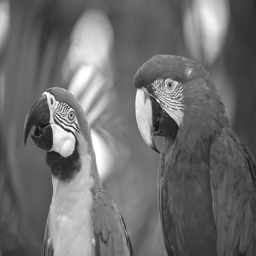

Caption: two birds are standing next to each other birds


In [2]:
# @title 1. Image → Text (BLIP)

release("sd", "audio")
image = load_default_image()
caption = caption_image(image)

display(image.resize((256, 256)))
print("Caption:", caption)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: D:\hf_home\hub\models--runwayml--stable-diffusion-v1-5\snapshots\451f4fe16113bff5a5d2269ed5ad43b0592e9a14\text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Prompt: a cat sitting on a windowsill, golden hour lighting


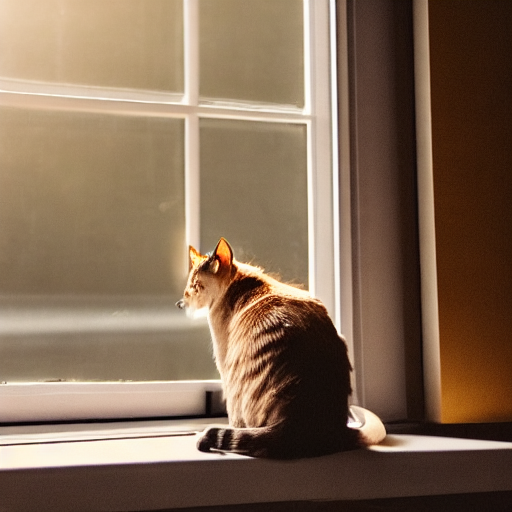

In [3]:
# @title 2. Text → Image (Stable Diffusion 1.5)

release("blip", "audio")

PROMPT = "a cat sitting on a windowsill, golden hour lighting"
image_t2i = generate_image(PROMPT, steps=20, guidance=7.5, seed=42)

image_t2i.save(OUT / "text_to_image.png")
print("Prompt:", PROMPT)
display(image_t2i)


In [4]:
# @title 3. Text → Audio (AudioLDM-S)

import scipy.io.wavfile

release("blip", "sd")

AUDIO_PROMPT = "a hammer hitting a wooden surface"
audio_t2a, SR = text_to_audio(AUDIO_PROMPT, seconds=5.0, steps=25)
scipy.io.wavfile.write(
    OUT / "text_to_audio.wav", rate=SR, data=(audio_t2a * 32767).astype(np.int16)
)

print(f"Prompt: {AUDIO_PROMPT} | sample rate: {SR} | duration: 5.0 s")
Audio(audio_t2a, rate=SR)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/205 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The AudioLDMPipeline has been deprecated and will not receive bug fixes or feature updates after Diffusers version 0.33.1. 


Prompt: a hammer hitting a wooden surface | sample rate: 16000 | duration: 5.0 s


In [5]:
# @title 4. Image → Audio (BLIP caption → AudioLDM-S)

release("sd", "audio")

# Шаг 1: Image → Text
image = globals().get("image")
if image is None:
    image = load_default_image()
caption = caption_image(image)
print("Caption:", caption)

# Шаг 2: Text → Audio (AudioLDM-S генерирует звуки, а не речь)
release("blip")
audio_prompt = f"sound of {caption}"
print("Audio prompt:", audio_prompt)
audio_i2a, SR = text_to_audio(audio_prompt, seconds=5.0, steps=25)
scipy.io.wavfile.write(
    OUT / "image_to_audio.wav", rate=SR, data=(audio_i2a * 32767).astype(np.int16)
)

Audio(audio_i2a, rate=SR)


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Caption: two birds are standing next to each other birds
Audio prompt: sound of two birds are standing next to each other birds


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/205 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The AudioLDMPipeline has been deprecated and will not receive bug fixes or feature updates after Diffusers version 0.33.1. 


Transcribed: He hoped there would be stew for dinner, turnips and carrots and bruised potatoes and fat mutton  pieces to be ladled out in thick, peppered, flower-fattened sauce.


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: D:\hf_home\hub\models--runwayml--stable-diffusion-v1-5\snapshots\451f4fe16113bff5a5d2269ed5ad43b0592e9a14\text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


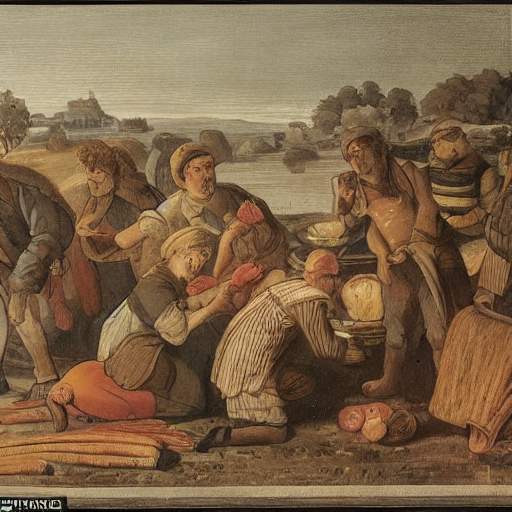

In [6]:
# @title 5. Audio → Image (faster-whisper → Stable Diffusion 1.5)

import urllib.request

from faster_whisper import WhisperModel

release("blip", "audio", "sd")

# Демо-аудио: короткая английская речь. Замените на свой файл при желании.
AUDIO_PATH = OUT / "speech_sample.flac"
if not AUDIO_PATH.exists():
    urllib.request.urlretrieve(
        "https://huggingface.co/datasets/Narsil/asr_dummy/resolve/main/1.flac",
        AUDIO_PATH,
    )

# Шаг 1: Audio → Text (faster-whisper, CPU int8; можно small.en / medium.en)
whisper = WhisperModel("base.en", device="cpu", compute_type="int8")
segments, _ = whisper.transcribe(str(AUDIO_PATH), beam_size=5)
transcription = " ".join(segment.text for segment in segments).strip()
print("Transcribed:", transcription)

del whisper
free_memory()

# Шаг 2: Text → Image
image_a2i = generate_image(
    f"a scene depicting: {transcription[:200]}", steps=20, guidance=7.5, seed=42
)
image_a2i.save(OUT / "audio_to_image.png")
display(image_a2i)


## Итог

Все связки отработали на инференсе, результаты сохранены в папку `outputs/`:

* `text_to_image.png` — генерация по текстовому промпту;
* `text_to_audio.wav` — звук по тексту;
* `image_to_audio.wav` — звук по картинке (через caption);
* `audio_to_image.png` — картинка по расшифровке речи.

**Заметки:**
* AudioLDM-S — модель генерации **звуковых эффектов**, речь она не синтезирует. Для «Image → Audio» она озвучивает описание сцены, а не дословно то, что на картинке.
* Если нужен звук качества выше — можно взять AudioLDM2, но ей нужно ~6 ГБ VRAM (на этой машине не помещается) либо CPU-оффлоад (сильно медленнее).
* Для `Audio → Image` можно взять `small.en` / `medium.en` в `WhisperModel(...)` — они уже в кэше.
